In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## t-sne

**Figure 3: t-SNE embedding of the penultimate-layer features of a ResNet-34 trained on CIFAR-10, for CIFAR-10 test samples.** Each color is one of the ten classes, 100 test samples each. All ten classes form clearly separated clusters, consistent with class-conditional Gaussian features.

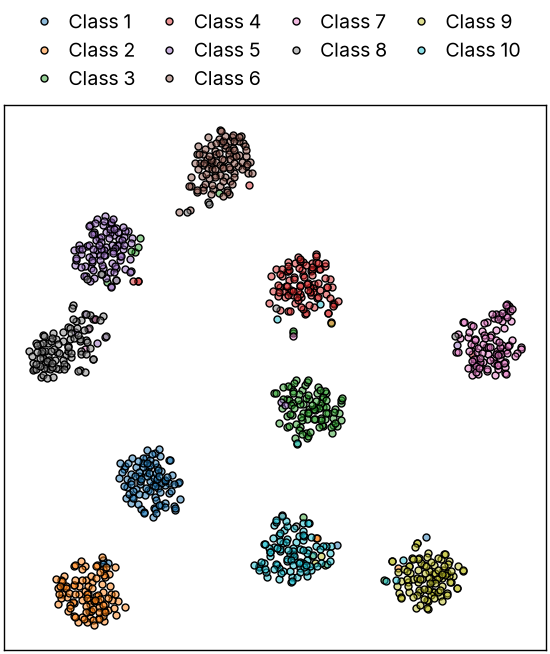

In [2]:
import matplotlib.colors

with open("../data/t-sne.json") as f:
    embedding = json.load(f)
class_colors = plt.get_cmap("tab10").colors

fig, ax = plt.subplots(figsize=(2.75, 2.75), layout="constrained")

for i, color in enumerate(class_colors, start=1):
    points = embedding[f"class_{i}"]
    ax.plot(points["x"], points["y"], "o", markeredgecolor=colors["ink"],
            markerfacecolor=(*matplotlib.colors.to_rgb(color), 0.5), linestyle="none", label=f"Class {i}")

ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=4, frameon=False)

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/t-sne.pdf")
fig.savefig("../outputs/t-sne.png")
plt.show()